PyTorch lab: train a tiny neural network

*   Loads the housing dataset from the pytorch dataset library
*   and builds a linear regression network using MLP





In [ ]:
import torch
import torch.nn as nn
from matplotlib import pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader


#load the dataset
housing = fetch_california_housing()
print(housing.data.shape, housing.target.shape)

#split the data into train+val(85%) and test(15%) parts
X_train_val, X_test, y_train_val, y_test = train_test_split(housing.data,
                                                            housing.target,
                                                            test_size = 0.15,
                                                            random_state=42)
#print(X_train_val.shape, X_test.shape)

#split the train_val data into train(85%) and val (15%) parts
X_train, X_valid, y_train, y_valid = train_test_split(X_train_val, y_train_val,
                                                      test_size = 0.15/0.85,
                                                      random_state=42)
print(X_train[0,0])

#Normalize and scale the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.fit_transform(X_valid)
X_test = scaler.fit_transform(X_test)

#print(f"X_train: {X_train.shape} X_valid:{X_valid.shape} X_test: {X_test.shape}")
#print(X_train[0,0])

(20640, 8) (20640,)
4.875


Convert features and labels into tensors


In [ ]:

#create tensors from ndarrays using pytorch conversion functions
X_train = torch.FloatTensor(X_train)
X_valid = torch.FloatTensor(X_valid)
X_test = torch.FloatTensor(X_test)
# create tensors for targets and also convert them to col vectors matching the final output layer of the MLP
y_train = torch.FloatTensor(y_train).reshape(-1, 1)
y_valid = torch.FloatTensor(y_valid).reshape(-1, 1)
y_test = torch.FloatTensor(y_test).reshape(-1,1)

# print the tensor shapes
#print(f"X_train={X_train.shape} X_valid={X_valid.shape} X_test={X_test.shape} y_train={y_train.shape} y_test={y_test.shape} ")
#print(X_train.dtype, X_train[0,1])

Check if we have the GPU available to use and then select the device based on it. We will store the device in the variable device and maybe use it later

Define a training function to be used for training the NN

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (f"device we will use = {device}")

# define the training loop for the MLP
def one_train (model, optimizer, loss_fn, X_train, y_train, X_valid, y_valid,
               n_epochs):
  errPlot = {"trn_loss":[], "vld_loss":[]}
  model.train()
  X_train, y_train = X_train.to(device), y_train.to(device)
  for epoch in range(n_epochs):
    y_pred = model(X_train)          # forward
    loss = loss_fn(y_pred, y_train)  # score mistakes

    optimizer.zero_grad()            # clear old grads
    loss.backward()                  # compute grads
    optimizer.step()                 # update weights

    #store the train loss in the errPlot dict for later plotting
    errPlot["trn_loss"].append(loss.item())
    print(f"Epoch {epoch+1}, Loss: {loss.item()}")

    # run eval on the validation data in each epoch
    model.eval()
    # move data to cuda if GPU is available
    X_valid, y_valid = X_valid.to(device), y_valid.to(device)
    with torch.no_grad():            # disable grad tracking
      vld_pred = model(X_valid)
      vld_loss = loss_fn(vld_pred, y_valid)
      errPlot["vld_loss"].append(vld_loss.item())

  #return the errPlot dictionary back for plotting later
  return errPlot


# define the training loop for the MLP
def train (model, optimizer, loss_fn, train_loader, n_epochs):
  model.train()
  for epoch in range(n_epochs):
    total_loss = 0
    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)          # forward
      loss = loss_fn(y_pred, y_batch)  # score mistakes
      total_loss += loss.item()        # calulate the total loss for the epoch

      optimizer.zero_grad()            # clear old grads
      loss.backward()                  # compute grads
      optimizer.step()                 # update weights

    mean_loss = total_loss/len(train_loader)
    print(f"Epoch {epoch+1}, Loss: {mean_loss()}")


device we will use = cpu


*   Build an MLP with nn.Linear and ReLU activation
*   Train with a loss function and optimizer
*   Uses 2 hidden layers and one output layer
*   Started testing with
    * Hidden layer 1 has 50 neurons and layer 2 has 40




In [ ]:
torch.manual_seed(42)  # used to add more deteminism and save related model info
# create the model uisng the nn.Linear and ReLU
n_features = X_train.shape[1]
model = nn.Sequential(
    nn.Linear(n_features, 80),
    nn.ReLU(),
    nn.Linear(80, 80),
    nn.ReLU(),
    nn.Linear(80, 1)
)

# move model to GPU if available
model.to(device)

# define the loss function and optimizer for the model
lossfn = nn.MSELoss()
learning_rate = 0.1  # also try using other rate higher or lower

# SGD optimizer
sgdOpt = torch.optim.SGD(model.parameters(), lr=learning_rate)

# Adam optimizer
adamOpt = torch.optim.Adam(model.parameters(), lr=0.03)

Print training loss across epochs


In [ ]:
# create data loader with batch size 32
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
#print (f"train_loader Len : {len(train_loader)}")

# call the model trainer
n_epoch = 30              # run traing fo these many iterations
#loss_plot = one_train(model,sgdOpt,lossfn,X_train,y_train,X_valid,y_valid,n_epoch)
loss_plot = one_train(model,adamOpt,lossfn,X_train,
                      y_train,X_valid,y_valid,n_epoch)

#train(model, sgdOpt, lossfn, train_loader, 20)
#train(model, adamOpt, lossfn, train_loader, 20)


Epoch 1, Loss: 5.106747150421143
Epoch 2, Loss: 1.9553725719451904
Epoch 3, Loss: 1.3164254426956177
Epoch 4, Loss: 0.8773144483566284
Epoch 5, Loss: 0.9521709680557251
Epoch 6, Loss: 0.8019928932189941
Epoch 7, Loss: 0.8255577087402344
Epoch 8, Loss: 0.7100110650062561
Epoch 9, Loss: 0.6265166997909546
Epoch 10, Loss: 0.6590370535850525
Epoch 11, Loss: 0.608645498752594
Epoch 12, Loss: 0.6000592708587646
Epoch 13, Loss: 0.5808436274528503
Epoch 14, Loss: 0.516157329082489
Epoch 15, Loss: 0.5215863585472107
Epoch 16, Loss: 0.4971272647380829
Epoch 17, Loss: 0.4732995927333832
Epoch 18, Loss: 0.4779461622238159
Epoch 19, Loss: 0.4447577893733978
Epoch 20, Loss: 0.4452664256095886
Epoch 21, Loss: 0.4409361481666565
Epoch 22, Loss: 0.42867395281791687
Epoch 23, Loss: 0.43004876375198364
Epoch 24, Loss: 0.4159952700138092
Epoch 25, Loss: 0.41448649764060974
Epoch 26, Loss: 0.4066920578479767
Epoch 27, Loss: 0.4049381613731384
Epoch 28, Loss: 0.4041496515274048
Epoch 29, Loss: 0.39599910378

Run Inference on the test set and print results for 2 examples

Predicted Value:        Traget Value:

In [ ]:
# run eval on the validation data in each epoch
model.eval()
with torch.inference_mode():
  test_pred = model(X_test)
  test_loss = lossfn(test_pred, y_test)
print(f"Test Loss : {test_loss.item()}")

ext_pred = 0
for i, item in enumerate(test_pred):
    if i < 2:
      print(f"Example {i+1} Predectied Value: {item}\tTarget Value: {y_test[i]}")
    elif item == y_test[i]:
      ext_pred +=1
print(f"\nNumber of correct predictions by the model = {ext_pred}")


Test Loss : 1.1464698314666748
Example 1 Predectied Value: tensor([0.3743])	Target Value: tensor([0.4770])
Example 2 Predectied Value: tensor([2.3759])	Target Value: tensor([0.4580])

Number of correct predictions by the model = 0


Plot training and validation loss across epochs

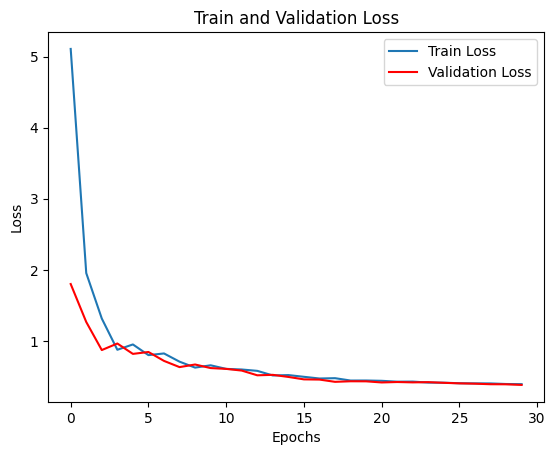

In [ ]:
x = [x for x in range(n_epoch)]

plt.plot(x, loss_plot["trn_loss"], '-', label="Train Loss")
plt.plot(x, loss_plot["vld_loss"], '-r', label="Validation Loss")
plt.legend(loc="upper right")

plt.title("Train and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

Reflections

*   Initially I hit the issue where i was getting Nan as the loss
    * reason that i did not reshape the target dataset to be in one column
    * I still got Nans as i did not scale but am not sure why?
*   Tested with different optimizers and different # of neurons
    * there is a threshold after which adding more neurons diverges and the loss stops reducing
    * Adam optimizer gives a better loss reduction as compared to SGD for this dataset
    * Next will test with other loss function and the classifier for the Forest cover example
*   Kept some data for validation and tried the validation in each epoch
    * Next test with adding the validation samples too to the training and see if it makes the model better
*   The performance is still bad as the predictions are way off :)

